# Introduction to the data class

`ProteinDataset` is an ordinary `torch.utils.data.Dataset` over one of the CSVs in `data/`. It
tokenises every sequence once, when it is constructed, and serves both of the project's targets
from the same `x`:

| Item | Shape | What it is |
|---|---|---|
| `x` | `(129,)` long | `<BOS>`, the residues, `<EOS>`, then `<PAD>` |
| `x_shifted` | `(129,)` long | `x` shifted left by one: the next-token target, `-1` past the end |
| `y` | scalar long | the family, as a class index |
| `length` | int | the number of residues, without the special tokens |


In [295]:
from protgen.data import ProteinDataset
from torch.utils.data import DataLoader

train_data = ProteinDataset(path_to_data="../data/train.csv")
val_data = ProteinDataset(path_to_data="../data/val.csv")
test_data = ProteinDataset(path_to_data="../data/test.csv")

print(f"Data class: {train_data}")

# Get tensors
X_train = train_data.tokens
y_train_labels = train_data.labels          # classification task
y_train_shifted = train_data.tokens_shifted # generative task

print(f"# Train data: \n Tokens shape: {X_train.shape}\n Labels (shape): {y_train_labels.shape} \n Shifted shape: {y_train_shifted.shape}")


# Inddexing
x, x_shifted, y, length = train_data[0]
print(f"# Sample 0: \nTokens: \n {x}\n Shifted: \n {x_shifted}\n Label: {y}\n Length: {length}")

# DataLoader
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)

# TestLoader
test_loader = DataLoader(test_data, batch_size=32, shuffle=True)

Data class: ProteinDataset(num_samples=16020, vocab_size=23, num_classes=3, max_length=129)
# Train data: 
 Tokens shape: torch.Size([16020, 129])
 Labels (shape): torch.Size([16020]) 
 Shifted shape: torch.Size([16020, 129])
# Sample 0: 
Tokens: 
 tensor([ 1, 13, 10, 11, 11, 16,  7, 14, 10, 10, 11, 14, 19,  8,  7,  3, 17, 15,
         3, 19, 12, 12, 20, 11, 12, 18, 16, 17,  7, 19, 18,  5, 10, 18, 12,  6,
        22, 16,  8, 11, 19, 10, 14, 12, 11,  9, 18,  3, 11, 18, 10, 13,  5, 10,
        13, 18, 12, 18, 10, 17, 15,  8, 19, 11,  7, 22, 10, 11,  3,  6,  8, 10,
         5,  6, 20, 16,  3, 10, 16, 12, 10, 16,  5, 22, 12, 22, 11,  6, 11, 12,
        10, 14, 22,  2,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0])
 Shifted: 
 tensor([13, 10, 11, 11, 16,  7, 14, 10, 10, 11, 14, 19,  8,  7,  3, 17, 15,  3,
        19, 12, 12, 20, 11, 12, 18, 16, 17,  7, 19, 18,  5, 10, 18, 12,  6, 22

## The vocabulary

The token ids are fixed in `protgen.data`, not inferred from the data, so an id means the same
residue in every run and checkpoint: `<PAD>` 0, `<BOS>` 1, `<EOS>` 2, then the 20 standard
residues in alphabetical order. `encode` and `decode` go between a residue string and a token
tensor, and `decode` drops the special tokens - so decoding either `x` or `x_shifted` gives the
protein back.

In [296]:
from protgen.data import AA, FAMILIES, IGNORE_INDEX, special_tokens

print(f"vocab ({train_data.vocab_size} tokens): {train_data.vocab}")
print(f"families: {train_data.fam_to_idx}")
print(f"padding is ignored in the loss with ignore_index={IGNORE_INDEX}")

sequence = train_data.df["sequence"][0]
tokens = train_data.encode(sequence)
print()
print(f"encode / decode round-trips: {train_data.decode(tokens) == sequence}")
print(f"and from the shifted target too:  {train_data.decode(x_shifted) == sequence}")

vocab (23 tokens): {'<PAD>': 0, '<BOS>': 1, '<EOS>': 2, 'A': 3, 'C': 4, 'D': 5, 'E': 6, 'F': 7, 'G': 8, 'H': 9, 'I': 10, 'K': 11, 'L': 12, 'M': 13, 'N': 14, 'P': 15, 'Q': 16, 'R': 17, 'S': 18, 'T': 19, 'V': 20, 'W': 21, 'Y': 22}
families: {'AcyP': 0, 'HPr': 1, 'HU': 2}
padding is ignored in the loss with ignore_index=-1

encode / decode round-trips: True
and from the shifted target too:  True


## The two tasks

Both losses read the same `x`. The generative one predicts every residue from the ones before it,
with `ignore_index` making the padding free of loss; the classification one predicts the family of
the whole sequence. Stand-ins for the logits below, since the model is yours to write.

In [297]:
import torch
import torch.nn.functional as F

x, x_shifted, y, length = next(iter(train_loader))
print(f"batch: x {tuple(x.shape)} {x.dtype}, x_shifted {tuple(x_shifted.shape)}, y {tuple(y.shape)}")

# Generative: one distribution over the vocabulary per position.
logits_gen = torch.randn(x.shape[0], train_data.vocab_size, train_data.max_length)
print(f"generative loss:     {F.cross_entropy(logits_gen, x_shifted, ignore_index=IGNORE_INDEX):.4f}")

# Classification: one distribution over the three families per sequence.
logits_fam = torch.randn(x.shape[0], len(FAMILIES))
print(f"classification loss: {F.cross_entropy(logits_fam, y):.4f}")

batch: x (32, 129) torch.int64, x_shifted (32, 129), y (32,)
generative loss:     3.5994
classification loss: 1.4670


## Next

Write your model in `src/protgen/models/`, and have your sampling code write a CSV with a
`sequence` column to `results/sequences/<name>.csv`. That is the only thing the evaluation asks
for:

```bash
uv run python eval/eval.py --samples results/sequences/mock_data.csv
```

`results/sequences/mock_data.csv` ships with the repo, so that command runs today. See
[`eval/README.md`](../eval/README.md) for what the numbers mean, and make the controls
(`eval/make_controls.py`) before reading any of them.

In [298]:
import torch
from torch import nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

In [299]:
hidden_layer_nodes = 50
#num_features = 3 # The three vakues in the sting of protein
num_features = train_data.vocab_size # The three vakues in the sting of protein, but this have I made as a array that is onehot encoded
num_output = train_data.vocab_size # The number of of possible values
num_embedding = 128 # The number of embedding dimensions

class Net(nn.Module):

    def __init__(self):
        super(Net, self).__init__()
        # Setting up variables, these variables are weights in your 
        # network that can be updated while running our graph.
        # Notice, to make a hidden layer, the weights need to have the 
        # following dimensionality:
        #   W[number_of_units_going_out, number_of_units_going_in]
        #   b[number_of_units_going_out]
        # in the example below we have 2 input units (num_features) and 2 output units (num_output)
        # so our weights become W[2, 2], b[2]
        # if we want to make a hidden layer with 100 units, we need to define the shape of the
        # first weight to W[100, 2], b[2] and the shape of the second weight to W[2, 100], b[2]
        
        # first layer
        #self.W_1 = nn.Parameter(torch.randn(num_output, num_features)) 
        #self.b_1 = nn.Parameter(torch.randn(num_output))
        self.embed = nn.Embedding(num_features, num_embedding)
        self.W_1 = nn.Parameter(torch.randn(hidden_layer_nodes, num_embedding*3)) 
        self.b_1 = nn.Parameter(torch.randn(hidden_layer_nodes))
            
        # second layer (to be completed as an exercise)
        # NB when you create a second layer, remember that you also must change parts of the first layer
        self.W_2 = nn.Parameter(torch.randn(hidden_layer_nodes, hidden_layer_nodes))
        self.b_2 = nn.Parameter(torch.randn(hidden_layer_nodes))

        self.W_3 = nn.Parameter(torch.randn(num_output, hidden_layer_nodes))
        self.b_3 = nn.Parameter(torch.randn(num_output))


        # He initializatopm fp weight followinf taking inspiration from figure 7.8 in Prince
        # Without having this, the exploding gradient problem ruined the training process (see Prince section 7.5)
        nn.init.kaiming_uniform_(self.W_1, nonlinearity="relu")
        nn.init.kaiming_uniform_(self.W_2, nonlinearity="relu")
        nn.init.kaiming_uniform_(self.W_3, nonlinearity="relu")

        nn.init.zeros_(self.b_1)
        nn.init.zeros_(self.b_2)
        nn.init.zeros_(self.b_3)
        
    def forward(self, x):
        # Setting up ops, these ops will define edges along our computational graph
        # The below ops will compute a logistic regression, 
        # but can be modified to compute a neural network
        #print(f"shape of x before embedding: {x.shape}")
        #print(x[0, :])
        x = self.embed(x) 
        #print(f"shape of x after embedding: {x.shape}")
        #print(x[0, :, :])
        x = x.flatten(start_dim=1)
        #print(f"shape of x after flatten: {x.shape}")
        #print(x[0, :])
        x = F.linear(x, self.W_1, self.b_1) # være rigtige dimensioner 
        #print(f"shape of x after 1 hidden layer: {x.shape}")
        #print(x[0, :])
        #print("Weight W1: ", self.W_1)
        #print("Weight b1: ", self.b_1)
        
        # second layer (to be completed as an exercise)
        # NB when you create a second layer, remember that you also must change parts of the first layer
        #x = F.linear(x, self.W_2, self.b_2)
        x = F.relu(x)
        x = F.linear(x, self.W_2, self.b_2)

        x = F.relu(x)
        x = F.linear(x, self.W_3, self.b_3)

        return F.softmax(x, dim=1) # x # F.softmax(x, dim=1) # softmax to be performed on the second dimension

net = Net()

In [300]:
# He initializatopm fp weight followinf figure 7.8 in Prince
# Without having this, the exploding gradient problem ruined the training process (see Prince section 7.5)
# He initialization of weights
# def weights_init(layer_in):
#     if isinstance(layer_in, nn.Linear):
#         nn.init.kaiming_normal_(layer_in.weight)
#         layer_in.bias.data.fill_(0.0)
# net.apply(weights_init)

In [301]:
def cross_entropy(ys, ts):
    # computing cross entropy per sample
    cross_entropy = -torch.sum(ts * torch.log(ys), dim=1, keepdim=False)
    # averaging over samples
    return torch.mean(cross_entropy)

In [302]:
import torch.optim as optim

optimizer = optim.SGD(net.parameters(), lr=1., momentum=0.9)

In [303]:
#def accuracy(ys, ts):
#    # making a one-hot encoded vector of correct (1) and incorrect (0) predictions
#    correct_prediction = torch.eq(torch.max(ys, 1)[1], torch.max(ts, 1)[1])
#    # averaging the one-hot encoded vector
#    return torch.mean(correct_prediction.float())
def accuracy(ys, ts):
    # making a one-hot encoded vector of correct (1) and incorrect (0) predictions
    correct_prediction = torch.eq(torch.max(ys, 1)[1], ts) # tr_targets is the last value and there there is not an extra index dimension
    # averaging the one-hot encoded vector
    return torch.mean(correct_prediction.float())

In [304]:
batch_size_ = 32*4
train_loader = DataLoader(train_data, batch_size=batch_size_, shuffle=True)
val_loader = DataLoader(val_data, batch_size=batch_size_, shuffle=True)

In [ ]:
size_of_traindata = len(train_data)

In [306]:
def onehot(t, num_classes):
    out = np.zeros((t.shape[0], num_classes))
    for row, col in enumerate(t):
        out[row, col] = 1
    return out

In [307]:
# x, x_shifted, y, length = next(iter(train_loader))
# x = F.pad(x, (2, 0, 0, 0)) # Zero padding with 2 columns to the left.
# #X_tr = x_shifted[:, 0:3]
# #y_tr = x[:, 0]
# #x = x.asnumpy()
# for i in range(x.shape[0]):
#     progress = 0
#     endOfString = 0
#     while endOfString != 2:
#         if (i == 0) and (progress == 0):
#             X_tr = x[i, 0:3]
#             y_tr = x_shifted[i, 0]
#         else:
#             X_tr = np.vstack((X_tr, x[i, (0+progress):(3+progress)]))
#             y_tr = np.vstack((y_tr, x_shifted[i, (0+progress)]))
#         endOfString = x_shifted[i, (0+progress)]
#         progress += 1

Epoch 0, Train Cost: 3.421	Val Cost: 3.191	 Val acc: 0.063
Epoch 10, Train Cost: 2.789	Val Cost: 2.792	 Val acc: 0.111
Epoch 20, Train Cost: 2.742	Val Cost: 2.718	 Val acc: 0.107
Epoch 30, Train Cost: 2.700	Val Cost: 2.677	 Val acc: 0.100
Epoch 40, Train Cost: 2.644	Val Cost: 2.602	 Val acc: 0.103
Epoch 50, Train Cost: 2.642	Val Cost: 2.619	 Val acc: 0.098
Epoch 60, Train Cost: 2.607	Val Cost: 2.624	 Val acc: 0.101
Epoch 70, Train Cost: 2.603	Val Cost: 2.555	 Val acc: 0.102
Epoch 80, Train Cost: 2.588	Val Cost: 2.565	 Val acc: 0.096
Epoch 90, Train Cost: 2.595	Val Cost: 2.565	 Val acc: 0.098
Epoch 100, Train Cost: 2.574	Val Cost: 2.572	 Val acc: 0.097
Epoch 110, Train Cost: 2.567	Val Cost: 2.549	 Val acc: 0.099
Epoch 120, Train Cost: 2.579	Val Cost: 2.541	 Val acc: 0.092
Epoch 130, Train Cost: 2.537	Val Cost: 2.539	 Val acc: 0.093
Epoch 140, Train Cost: 2.538	Val Cost: 2.531	 Val acc: 0.093


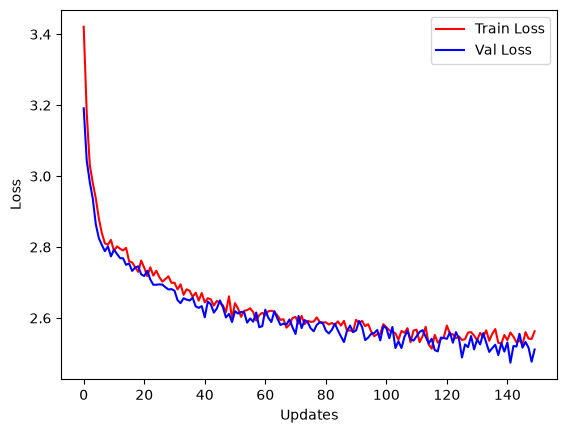

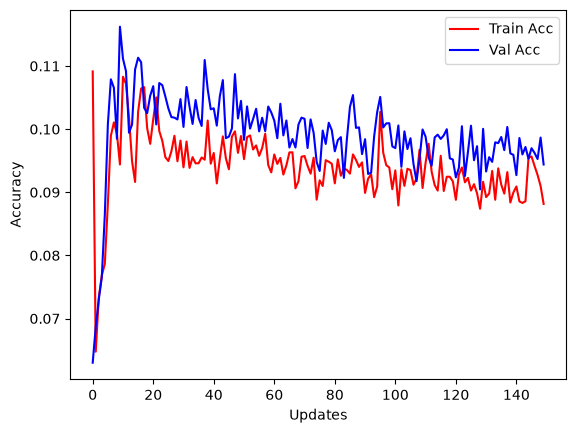

In [ ]:
# number of training passses
num_epochs = int(np.floor(size_of_traindata/batch_size_))
num_epochs = 150
#num_epochs = 
# store loss and accuracy for information
train_losses, val_losses, train_accs, val_accs = [], [], [], []
test_losses, test_accs = [], []

def pred(X):
    """ Compute graph's prediction and return numpy array
    
    Parameters
    ----------
    X : numpy.ndarray
    
    Returns
    -------
    numpy.ndarray
    """
    X = torch.from_numpy(X)
    y = net(X)
    return y.data.numpy()

# training loop
for e in range(num_epochs):
    x, x_shifted, y, length = next(iter(train_loader))
    x = F.pad(x, (2, 0, 0, 0)) # Zero padding with 2 columns to the left.
    for i in range(x.shape[0]):
        progress = 0
        endOfString = 0
        while endOfString != 2:
            if (i == 0) and (progress == 0):
                X_tr = x[i, 0:3]
                y_tr = x_shifted[i, 0]
            else:
                X_tr = np.vstack((X_tr, x[i, (0+progress):(3+progress)]))
                y_tr = np.vstack((y_tr, x_shifted[i, (0+progress)]))
            endOfString = x_shifted[i, (0+progress)]
            progress += 1

    # get training input and expected output as torch Variables and make sure type is correct
    tr_input = torch.from_numpy(X_tr) # torch.from_numpy(onehot(X_tr, num_output)).float() #X_tr#torch.from_numpy(onehot(X_tr, num_output)).float()# torch.from_numpy(X_tr)
    tr_targets = torch.from_numpy(y_tr) #torch.from_numpy(onehot(y_tr, num_output)).float() #y_tr#torch.from_numpy(onehot(y_tr, num_output)).float()
    
    # zeroize accumulated gradients in parameters
    optimizer.zero_grad()
    # predict by running forward pass
    #print(X_tr.shape)
    #print(tr_input.shape)
    tr_output = net(tr_input)
    # compute cross entropy loss
    #tr_targetsOutput = net.embed(tr_targets)
    tr_targets_oneHot = torch.Tensor(onehot(tr_targets, num_output)) # Make it one hot such that the code knows which one is the correct one for the cross entropy calculation.
    tr_loss = cross_entropy(tr_output, tr_targets_oneHot) #F.cross_entropy(tr_output, tr_targets.flatten()) #cross_entropy(tr_output, tr_targets)
    # compute gradients given loss
    tr_loss.backward()
    # update the parameters given the computed gradients
    optimizer.step()
    train_acc = accuracy(tr_output, tr_targets)
    
    # store training loss
    train_losses.append(tr_loss.data.numpy())
    train_accs.append(train_acc)

    x_, x_shifted_, y_, length_ = next(iter(val_loader))
    x_ = F.pad(x_, (2, 0, 0, 0)) # Zero padding with 2 columns to the left.
    for i in range(x_.shape[0]):
        progress = 0
        endOfString = 0
        while endOfString != 2:
            if (i == 0) and (progress == 0):
                X_val = x_[i, 0:3]
                y_val = x_shifted_[i, 0]
            else:
                X_val = np.vstack((X_val, x_[i, (0+progress):(3+progress)]))
                y_val = np.vstack((y_val, x_shifted_[i, (0+progress)]))
            endOfString = x_shifted_[i, (0+progress)]
            progress += 1
    # get validation input and expected output as torch Variables and make sure type is correct
    val_input = torch.from_numpy(X_val) # torch.from_numpy(onehot(X_val, num_output)).float()  #torch.from_numpy(X_val)
    val_targets = torch.from_numpy(y_val)  #torch.from_numpy(onehot(y_val, num_output)).float()
    
    # predict with validation input
    val_output = net(val_input)
    # compute loss and accuracy
    val_targets_oneHot = torch.Tensor(onehot(val_targets, num_output)) # Make it one hot such that the code knows which one is the correct one for the cross entropy calculation.
    val_loss = cross_entropy(val_output, val_targets_oneHot) #F.cross_entropy(val_output, val_targets.flatten()) #cross_entropy(val_output, val_targets)
    #val_loss = cross_entropy(val_output, val_targets)
    val_acc = accuracy(val_output, val_targets)
    
    # store loss and accuracy
    val_losses.append(val_loss.data.numpy())
    val_accs.append(val_acc.data.numpy())

    # SAME FOR TEST DATA:
    x_, x_shifted_, y_, length_ = next(iter(test_loader))
    x_ = F.pad(x_, (2, 0, 0, 0))  # Zero padding with 2 columns to the left.

    for i in range(x_.shape[0]):
        progress = 0
        endOfString = 0
        while endOfString != 2:
            if (i == 0) and (progress == 0):
                X_test = x_[i, 0:3]
                y_test = x_shifted_[i, 0]
            else:
                X_test = np.vstack((X_test, x_[i, (0 + progress):(3 + progress)]))
                y_test = np.vstack((y_test, x_shifted_[i, (0 + progress)]))

            endOfString = x_shifted_[i, (0 + progress)]
            progress += 1

    # Get test input and expected output as torch tensors
    test_input = torch.from_numpy(X_test)
    test_targets = torch.from_numpy(y_test)

    # Predict with test input
    test_output = net(test_input)

    # Compute loss and accuracy
    test_targets_oneHot = torch.Tensor(onehot(test_targets, num_output))
    test_loss = cross_entropy(test_output, test_targets_oneHot)
    test_acc = accuracy(test_output, test_targets)

    # Store loss and accuracy
    test_losses.append(test_loss.data.numpy())
    test_accs.append(test_acc.data.numpy())
    
    if e % 10 == 0:
        print("Epoch %i, "
              "Train Cost: %0.3f"
              "\tVal Cost: %0.3f"
              "\t Val acc: %0.3f" % (e, 
                                     train_losses[-1],
                                     val_losses[-1],
                                     val_accs[-1]))
        
        
## get test input and expected output
#te_input = torch.from_numpy(X_te)
#te_targets = torch.from_numpy(onehot(y_te, num_output)).float()
## predict on testset
#te_output = net(te_input)
## compute loss and accuracy
#te_loss = cross_entropy(te_output, te_targets)
#te_acc = accuracy(te_output, te_targets)
#print("\nTest Cost: %0.3f\tTest Accuracy: %0.3f" % (te_loss.data.numpy(), te_acc.data.numpy()))

plt.figure()
epoch = np.arange(len(train_losses))
plt.plot(epoch, train_losses, 'r', label='Train Loss')
plt.plot(epoch, val_losses, 'b', label='Val Loss')
plt.legend()
plt.xlabel('Updates')
plt.ylabel('Loss')
plt.show()

plt.figure()
plt.plot(epoch, train_accs, 'r', label='Train Acc')
plt.plot(epoch, val_accs, 'b', label='Val Acc')
plt.legend()
plt.xlabel('Updates')
plt.ylabel('Accuracy')
plt.show()

In [310]:
best_index = int(np.argmax(val_accs))

print("Best validation accuracy:", val_accs[best_index])
print("Test accuracy at that epoch:", test_accs[best_index])
print("Test loss at that epoch:", test_losses[best_index])

Best validation accuracy: 0.116224855
Test accuracy at that epoch: 0.11066253
Test loss at that epoch: 2.7775548


In [196]:
# Create reverse mapping: index -> token
idx_to_token = {v: k for k, v in train_data.vocab.items()}

In [242]:
# With trained model, generate seqeunces:
max_length=129
ole_done_done = [[]]
for j in range(200): # Generate 10 sequences
    ole = torch.Tensor([[0,0,1]]).int()
    ole_done = [1]
    for i in range(max_length-1):
        tr_output = net(ole)
        # next_token = tr_output.argmax() NOT ARGMAX but a smapling over the dsitribution. Otherwise we would always generate the same string! We need this wee bit of "noise" to make this a generative model that makes snese.
        # Make sure that it does not take a padding or <begin of string> token:
        GoodToken = True
        while GoodToken:
            next_token = torch.multinomial(tr_output, num_samples=1)
            if next_token.item() != 0 and next_token.item() != 1:
                GoodToken = False
        #next_token = torch.multinomial(tr_output, num_samples=1)
        if next_token.item() == 2: # If the next token is the end of sequence token, then we stop generating.
                    break
        ole = torch.cat(
            (ole[:, 1:], next_token),
            dim=1
        )
        ole_done.append(next_token[0].item())
        # if next_token.item() == 2: # If the next token is the end of sequence token, then we stop generating.
        #     break
    #print(f"Generated sequence {j+1}: {ole_done}")
    ole_done = ole_done[1:] # remove beging of string token
    tokens = [idx_to_token[i] for i in ole_done]
    ole_done_done.append("".join(tokens))
ole_done_done = ole_done_done[1:] # Remove the first black sequence this variable was initalised with.

In [243]:
ole_done_done

['MTTDGTSDLRQRTAVYDENGEDLPAFKSELEMRATRVDAPAGTAK',
 'MNKSDIAKYP',
 'MKNLEDFNIIISAGGEELHLAKGDTVSGRVGTSIMGLLGAVTSWNAEHSRERYAARSALGPY',
 'MSVNAAGKAMIQAVAALDIAAISDQCVK',
 'MNKSDRSASVTICVRKGRVTGETAIQRKLAEAYDMTVSVLIKEDIDSGDWSSGKVQGVGFGTFSSKIVPKFKYGKVQGVGFRYTTQDDGNIEGNAIMDGAQLLLLLRKNVAIPAPSAKEAGVDVPAFG',
 'MADFGKFKRPAMAVEEDLINKQQAILSSYKATIADAAHLHDGESEGEAVAEGEKQDLDAGKNIAKDMIAKAVKFADFYSFIMSFVPYTGPEGKEVTGPQSLQTIKIAAAEKTKTPAGLGIDNPGFPRT',
 'MSEQANRRGLHARPAAEISGFVRASTEDVVEGRNPKTGRNGEIRTERLSGF',
 'MNKYDWHAQPLEGPKDLSALKPEKARTARHFEIRVQGVGFRRRNDPYQGAGAVEAVTEAVEIVNSDLVAGKKADFAVKRGHLKPLAEGAIEKEDGRVGREETTLVGKGRRSKLASAKRGPEALVICGR',
 'MQTIGLHARAARHGLNKSGLTGAEKSVLGLGESIMARGPRGGDPVRGDGAESEGDKAMQVAKGQRDREIFASEGDPIVNMPETTANPGFKIAKILAERRLVGLLMLD',
 'MNKTHNLMKFRNVQKKTLVGFRTLVDHGFMTKKVRKQVQGVGFRFSAYFVDVKQEFTEFPQFKEGTTIPAKKELDALPGVQGIKTTTQRGRNPKTGYKFFED',
 'MSQRQELDRLAEGPPAAMITNRLGLGIPHTGEIEVRLAKKCVTSGEGGPREGPELVEAVVSGRVRGSQTIAKSVNGEKVEVGFRYLR',
 'MTEEE',
 'MNKSKDALANGHRSARRIMMLAAGPPPNLENISKISAGKGLKEIVANRIQAIVDIDI

In [244]:
# Make the CSV file:
import csv

with open('../results/sequences/generated_sequences_MLP.csv', 'w', newline='') as file:
    writer = csv.writer(file)
    writer.writerow(['sequence'])
    for seq in ole_done_done:
        writer.writerow([seq])

In [238]:
len('MNKSKGANEITASQGGITGEEDGSVELEEFSAFDKLAVADDVVGEEDPQTGRNPRTGRSPIAARVEAAGASDRETVAARGYVRYFVSARITALGVEITVEAVNSKGGSIPAGAKKGPAEAEGPVEATD')

128